# Классификация новостей с помощью символьных n-грамм

Учебный проект по курсу NLP на факультете биоинженерии и биоинформатики МГУ.

**Задача:** классифицировать новости из AG News Dataset по четырём тематикам: World, Sport, Business и Science.

**Подход:** тексты представляются TF-IDF-признаками на основе символьных n-грамм, после чего обучается наивный байесовский классификатор MultinomialNB. Тип анализатора и диапазон n-грамм подбираются с помощью пятикратной кросс-валидации.

**Результат:** accuracy на отложенной тестовой выборке — **0,8997**, macro F1 — **0,8995**. Подробные результаты и ограничения эксперимента приведены в конце блокнота.

## Загрузка данных

Используется [предобработанная версия AG News Dataset](https://github.com/Xeanst/NLP_course_FBB/blob/main/data/news_preprocessed.csv), подготовленная для курса. Файл содержит 127 600 новостей и загружается автоматически при первом запуске блокнота.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

DATA_URL = (
    'https://raw.githubusercontent.com/Xeanst/NLP_course_FBB/'
    'main/data/news_preprocessed.csv'
)
DATA_PATH = Path('news_preprocessed.csv')

if not DATA_PATH.exists():
    print('Загрузка данных...')
    urlretrieve(DATA_URL, DATA_PATH)
else:
    print('Файл с данными уже загружен.')

Загружаем CSV-файл в pandas DataFrame и проверяем его размер и структуру.

In [2]:
import pandas as pd

news = pd.read_csv('news_preprocessed.csv')
print(f'Размер датасета: {news.shape}')
news.head()

Размер датасета: (127600, 5)


,Class Label,Title,Description,Class Index,Summary
0,Business,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindli...",2,wall bear claw back black reuters reuters wall...
1,Business,Carlyle Looks Toward Commercial Aerospace (Reu...,Reuters - Private investment firm Carlyle Grou...,2,carlyle look toward commercial aerospace reute...
2,Business,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\ab...,2,oil economy cloud stock outlook reuters reuter...
3,Business,Iraq Halts Oil Exports from Main Southern Pipe...,Reuters - Authorities have halted oil export\f...,2,iraq halt oil export main southern pipeline re...
4,Business,"Oil prices soar to all-time record, posing new...","AFP - Tearaway world oil prices, toppling reco...",2,oil price soar record pose new menace u econom...


Выделяем предобработанные тексты и индексы тематических классов.

In [3]:
X = news['Summary']
y = news['Class Index']

X.head(), y.head()

(0    wall bear claw back black reuters reuters wall...
 1    carlyle look toward commercial aerospace reute...
 2    oil economy cloud stock outlook reuters reuter...
 3    iraq halt oil export main southern pipeline re...
 4    oil price soar record pose new menace u econom...
 Name: Summary, dtype: object,
 0    2
 1    2
 2    2
 3    2
 4    2
 Name: Class Index, dtype: int64)

## Разделение данных

Разделяем данные на обучающую (75%) и тестовую (25%) выборки. Стратификация сохраняет исходное соотношение классов, а `random_state=42` обеспечивает воспроизводимость разбиения.

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print(f'Обучающая выборка: {X_train.shape[0]} текстов')
print(f'Тестовая выборка: {X_test.shape[0]} текстов')

Обучающая выборка: 95700 текстов
Тестовая выборка: 31900 текстов


## Подбор гиперпараметров

Объединяем векторизацию и классификацию в единый `Pipeline`. Это позволяет выполнять векторизацию отдельно внутри каждого фолда кросс-валидации и корректно оценивать весь процесс обучения модели.

Для представления текста используем `TfidfVectorizer` с `min_df=5`, для классификации — `MultinomialNB`.

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

pipeline = Pipeline([
    ('vect', TfidfVectorizer(min_df=5)),
    ('clf', MultinomialNB())
])

pipeline

Pipeline(steps=[('vect', TfidfVectorizer(min_df=5)), ('clf', MultinomialNB())])

Сравниваем символьные n-граммы двух типов:

- `char` — строятся по всему тексту, включая стыки слов;
- `char_wb` — строятся только внутри границ слов.

Для каждого типа анализатора проверяем четыре диапазона n-грамм.

In [6]:
parameters = {
    'vect__analyzer': ['char', 'char_wb'],
    'vect__ngram_range': [(2, 4), (3, 5), (4, 6), (3, 6)]
}

Перебираем восемь комбинаций параметров с помощью `GridSearchCV`. Качество оценивается по средней accuracy на пятикратной кросс-валидации; тестовая выборка на этом этапе не используется.

In [7]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=parameters,
    scoring='accuracy',
    cv=5,
    n_jobs=2,
    pre_dispatch=2,
    verbose=1,
    error_score='raise'
)

grid_search.fit(X_train, y_train)

print('Лучшие параметры:', grid_search.best_params_)
print(f'Лучшая средняя accuracy на кросс-валидации: {grid_search.best_score_:.4f}')

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Лучшие параметры: {'vect__analyzer': 'char', 'vect__ngram_range': (4, 6)}
Лучшая средняя accuracy на кросс-валидации: 0.8961


### Анализ результатов кросс-валидации

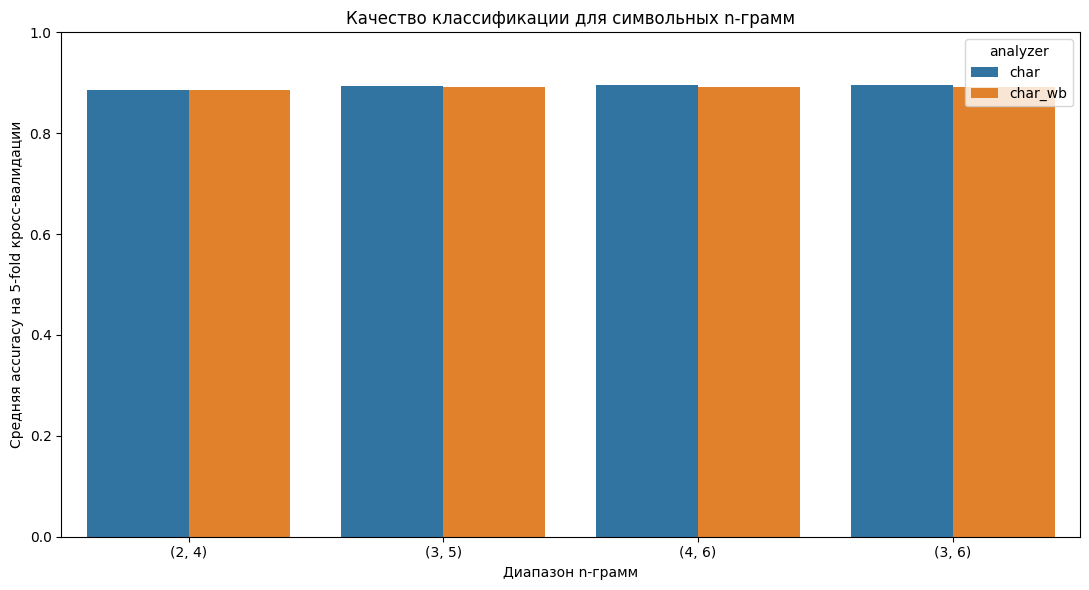

,analyzer,ngram_range,mean_test_score,std_test_score,rank_test_score
2,char,"(4, 6)",0.896071,0.002352,1
3,char,"(3, 6)",0.895099,0.002039,2
1,char,"(3, 5)",0.893114,0.001989,3
5,char_wb,"(3, 5)",0.892466,0.002315,4
6,char_wb,"(4, 6)",0.892435,0.002266,5
7,char_wb,"(3, 6)",0.892330,0.002274,6
4,char_wb,"(2, 4)",0.886364,0.001864,7
0,char,"(2, 4)",0.885747,0.001925,8


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

cv_results = pd.DataFrame(grid_search.cv_results_)
cv_results['ngram_range'] = cv_results['param_vect__ngram_range'].astype(str)
cv_results['analyzer'] = cv_results['param_vect__analyzer']

plt.figure(figsize=(11, 6))
sns.barplot(
    data=cv_results,
    x='ngram_range',
    y='mean_test_score',
    hue='analyzer',
    errorbar=None
)
plt.title('Качество классификации для символьных n-грамм')
plt.xlabel('Диапазон n-грамм')
plt.ylabel('Средняя accuracy на 5-fold кросс-валидации')
plt.ylim(0, 1)
plt.legend(title='analyzer')
plt.tight_layout()
plt.show()

cv_results[[
    'analyzer', 'ngram_range', 'mean_test_score', 'std_test_score', 'rank_test_score'
]].sort_values('rank_test_score')

## Финальная модель

Используем пайплайн с параметрами, показавшими лучшую среднюю accuracy на кросс-валидации. После подбора параметров он уже обучен на всей обучающей выборке.

In [9]:
best_pipeline = grid_search.best_estimator_
best_pipeline

Pipeline(steps=[('vect',
                 TfidfVectorizer(analyzer='char', min_df=5,
                                 ngram_range=(4, 6))),
                ('clf', MultinomialNB())])

Оцениваем финальную модель на отложенной тестовой выборке и выводим метрики по каждому классу.

In [10]:
from sklearn.metrics import accuracy_score, classification_report

# best_estimator_ уже обучен на всей обучающей выборке после GridSearchCV.
y_pred = best_pipeline.predict(X_test)

# Индексы и названия классов берём из данных, не задавая их вручную.
label_table = (
    news[['Class Index', 'Class Label']]
    .drop_duplicates()
    .sort_values('Class Index')
)
class_indices = label_table['Class Index'].tolist()
class_names = label_table['Class Label'].tolist()

print(f'Accuracy на тестовой выборке: {accuracy_score(y_test, y_pred):.4f}')
print(classification_report(
    y_test,
    y_pred,
    labels=class_indices,
    target_names=class_names,
    digits=4,
    zero_division=0
))

Accuracy на тестовой выборке: 0.8997
              precision    recall  f1-score   support

       World     0.9153    0.8851    0.9000      7975
       Sport     0.9448    0.9720    0.9582      7975
    Business     0.8621    0.8735    0.8678      7975
     Science     0.8761    0.8682    0.8722      7975

    accuracy                         0.8997     31900
   macro avg     0.8996    0.8997    0.8995     31900
weighted avg     0.8996    0.8997    0.8995     31900



## Выводы

Лучшей в рамках заданной сетки оказалась конфигурация `analyzer='char'` с диапазоном n-грамм `(4, 6)`. Её средняя accuracy на пятикратной кросс-валидации составила **0,8961** при стандартном отклонении **0,0024**. На отложенной тестовой выборке итоговый пайплайн достиг accuracy **0,8997** и macro F1 **0,8995**.

По отдельным классам F1-score составил: World — **0,9000**, Sport — **0,9582**, Business — **0,8678**, Science — **0,8722**. Таким образом, в рамках этого эксперимента лучше всего классифицировались спортивные новости, а для деловых и научных новостей качество оказалось ниже.

Более длинные символьные фрагменты показали более высокое качество, чем диапазон `(2, 4)`, однако этот вывод относится только к проверенной сетке параметров и фиксированному `min_df=5`. Небольшая разница между `char` и `char_wb` не позволяет без дополнительного статистического анализа утверждать, что один анализатор устойчиво превосходит другой.

Тестовая выборка не участвовала в подборе параметров и использовалась только для финальной оценки. Дальнейшими шагами могли бы стать сравнение с моделями на словесных n-граммах, анализ матрицы ошибок и проверка других классификаторов.